In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [12]:
# Given constants
m = 940e6
hbar_c = 1973.27
D = 0.755501
alpha = 1.44
r0 = 0.131349
A = hbar_c**2/(2*m)

In [13]:
# Constructing Hamiltonian matrix
def hamiltonian_matrix(n, dr, potential_values):

    """To construct the Hamiltonian matrix we need:
        n : number of interior grid points
        dr : grid spacing
        potential_values : potential energy at every grid point
    """

    # Kinetic Matrix
    kinetic_matrix = np.zeros((n, n))

    for i in range(n):
        kinetic_matrix[i,i] = -2
        if i+1 < n:
            kinetic_matrix[i+1,i] = kinetic_matrix[i,i+1] = 1
    kinetic_energy = -A*kinetic_matrix/dr**2

    # Potential Energy Matrix
    potential_energy = np.diag(potential_values)
    hamiltonian = kinetic_energy + potential_energy
    return hamiltonian

In [26]:
def morse_potential(r, D, alpha, r0):
    rp = r-r0
    potential = D*(np.exp(-2*alpha*rp)- np.exp(-alpha*rp))
    return potential

In [27]:
# Solving and plotting
def solve_and_plot(ri, rf, interior_points, state_number, alpha, r0):

    if interior_points <= 0:
        raise ValueError("interior_points must be positive.")

    if state_number < 0 or state_number >= interior_points:
        raise ValueError("Invalid state_number.")

    dr = (rf-ri)/(interior_points+1)
    interior_grid = np.linspace(ri+dr, rf-dr, interior_points)
    potential = morse_potential(interior_grid, D, alpha, r0)
    hamiltonian = hamiltonian_matrix(interior_points, dr, potential)

    # Calculating eigenvalues and eigenvectors
    energy, wavevector = np.linalg.eigh(hamiltonian)

    energy_value = energy[state_number]
    u = wavevector[:,state_number]
    # Making wavefunction positive
    if u[np.argmax(np.abs(u))] < 0:
        u = -u

    # Normalising wavefunction
    norm = np.sum(np.abs(u)**2)*dr
    u_normalized = u/np.sqrt(norm)

    # Calculating radial wavefunction R(r) = u(r)/r
    R = u_normalized/interior_grid

    return interior_grid, R, energy_value

Ground state energy = -0.16143815292126293 eV
Ground state energy = -1.614e-07 MeV


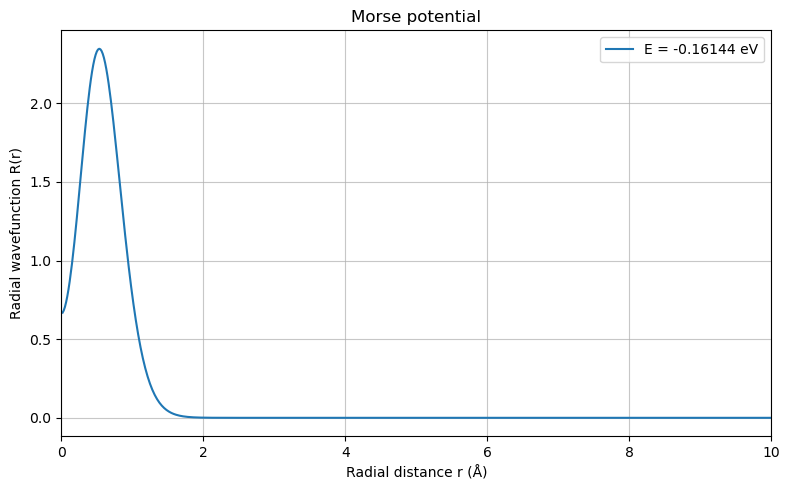

In [30]:
ri = 0
rf = 10
interior_points = 600
state_number = 0
grid, R, energy = solve_and_plot(ri, rf, interior_points, state_number, alpha, r0)

# Printing ground state energy
print("Ground state energy =", energy, "eV")
print("Ground state energy =",
      format(energy/1e6, '.3e'), "MeV")

# Plotting
plt.figure(figsize=(8,5))
plt.plot(grid, R, label=f"E = {energy:.5f} eV")
plt.xlabel("Radial distance r (Å)")
plt.ylabel("Radial wavefunction R(r)")
plt.title("Morse potential")
plt.xlim(0,10)
plt.legend()
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()